

**Membres du binôme :** Miloud Meziane
**Date :** 11/12/2025



## 0. Configuration de l'environnement

Pour réaliser ce TP, nous utilisons l'écosystème Python scientifique standard.
Nous importons ici l'ensemble des librairies nécessaires :
* **Pandas et Numpy** : Pour la manipulation de données (DataFrames, matrices).
* **Matplotlib** : Pour la visualisation graphique (courbes ROC, histogrammes).
* **Scikit-Learn** : Pour l'ensemble des algorithmes d'apprentissage (Classification, Preprocessing, Validation).

Nous configurons également l'environnement pour améliorer la lisibilité des sorties (suppression de la notation scientifique et des avertissements non critiques).

In [2]:
# ============================================================
# 0. IMPORTS ET CONFIGURATION GÉNÉRALE
# ============================================================

# 1. Librairies standards (Data Science & Système)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import pickle  # Pour sauvegarder le pipeline (Question 7)
import json    # Pour manipuler les données de l'API (Question 9)
import requests # Pour tester l'API (Question 9)

# 2. Scikit-Learn : Modèles d'apprentissage
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier

# 3. Scikit-Learn : Préparation des données (Preprocessing)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer # Pour traiter les valeurs manquantes (Partie II)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA


# 4. Scikit-Learn : Évaluation et Sélection
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, roc_auc_score, roc_curve, make_scorer

# 5. Explicabilité (Demandé à la Question 5)
try:
    import shap
except ImportError:
    print("⚠️ Attention : La librairie SHAP n'est pas installée. (pip install shap)")

# ============================================================
# CONFIGURATION
# ============================================================

# Ignorer les avertissements (warnings) inutiles pour garder le notebook propre
warnings.filterwarnings('ignore')

# Configuration de Numpy : 
# - threshold : permet d'afficher plus d'éléments dans les tableaux
# - suppress : empêche la notation scientifique (ex: 1.2e-4) pour plus de lisibilité
np.set_printoptions(threshold=10000, suppress=True)

print("✅ Environnement configuré et librairies chargées.")

/home/meziane/anaconda3/envs/tp_ml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Environnement configuré et librairies chargées.


## I. Apprentissage supervisé : Feature engineering et Classification

### 1. Chargement des données et préparation

**Objectif :** Importer le jeu de données `credit_scoring.csv`, le convertir en tableau Numpy, analyser la répartition des classes et diviser les données en deux parties égales (50% apprentissage, 50% test).

**Méthodologie :**
* Utilisation de la librairie **Pandas** pour la lecture du fichier (séparateur `;`).
* Transformation du DataFrame en **Numpy Array** (`.values`) pour être compatible avec Scikit-Learn.
* Séparation des variables descriptives (**X**) et de la cible à prédire (**y**).
* Calcul du pourcentage d'exemples positifs et négatifs.
* Division de l'échantillon avec `train_test_split` (`test_size=0.5` et `random_state=1` pour la reproductibilité).

In [3]:
def load_and_split_data(filename, sep=';'):
    """
    Charge, analyse et sépare les données.
    Affiche explicitement les dimensions pour prouver la séparation X/y.
    """
    # 1. Chargement et Transformation
    try:
        df = pd.read_csv(filename, sep=sep)
    except:
        df = pd.read_csv(filename, sep=',')
    
    # Transformation en Numpy Array (.values)
    data = df.values
    
    # Séparation en deux tableaux différents (Consigne respectée)
    X = data[:, :-1].astype(float)
    y = data[:, -1].astype(float)
    
    # 2. Analyse des propriétés
    n_total = len(y)
    n_pos = np.sum(y == 1)
    n_neg = np.sum(y == 0)
    
    print(f"--- Analyse du jeu de données ---")
    print(f"Taille de l'échantillon (df.shape) : {df.shape}")
    
    # Preuve que X et y sont bien séparés
    print(f"Taille de X (Features)             : {X.shape}") 
    print(f"Taille de y (Target)               : {y.shape}")
    
    # Pourcentages positifs ET négatifs
    print(f"Répartition : {n_pos} Positifs ({n_pos/n_total:.2%}) / {n_neg} Négatifs ({n_neg/n_total:.2%})")

    # 3. Split (Avec Stratify = Meilleure pratique, respecte random_state=1)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.5, random_state=1, stratify=y
    )
    
    print("-" * 30)
    print(f"Données d'entraînement (X_train) : {X_train.shape}")
    print(f"Données de test (X_test)         : {X_test.shape}")
    
    return X_train, X_test, y_train, y_test

# Exécution
X_train, X_test, y_train, y_test = load_and_split_data("credit_scoring.csv")

--- Analyse du jeu de données ---
Taille de l'échantillon (df.shape) : (4375, 14)
Taille de X (Features)             : (4375, 13)
Taille de y (Target)               : (4375,)
Répartition : 3159 Positifs (72.21%) / 1216 Négatifs (27.79%)
------------------------------
Données d'entraînement (X_train) : (2187, 13)
Données de test (X_test)         : (2188, 13)


### 2. Apprentissage et évaluation de modèles

**Objectif :** Entraîner trois algorithmes (CART, KNN, MLP) et comparer leurs performances sur les données brutes.

**Définition des fonctions :**
Conformément à l'énoncé, nous avons défini :
1.  Un **dictionnaire** `clfs` contenant les modèles avec les hyperparamètres imposés (ex: `k=5` pour KNN, `random_state=1` pour la reproductibilité).
2.  Une fonction **`evaluation`** qui affiche la matrice de confusion, trace la courbe ROC et calcule les métriques.
3.  Une fonction **`run_classifiers_train_test`** qui orchestre l'apprentissage et retourne le meilleur modèle.

**Choix du Score Final :**
L'énoncé demande un score moyen entre l'Accuracy et "le meilleur critère entre le Rappel et la Précision".
* **Notre choix :** La **Précision**.
* **Justification :** Dans le crédit scoring, le risque majeur est d'accorder un prêt à un mauvais payeur (Faux Positif). Maximiser la Précision permet de minimiser ce risque financier, quitte à être plus sélectif.
* **Formule :** `Score = (Accuracy + Précision) / 2`

=== RÉSULTATS DONNÉES BRUTES ===



--- CART ---
Matrice :
[[ 297  311]
 [ 319 1261]]
Accuracy : 0.712 | Précision : 0.802 | Rappel : 0.798
AUC      : 0.643
👉 Score Final : 0.757

--- KNN ---
Matrice :
[[ 180  428]
 [ 221 1359]]
Accuracy : 0.703 | Précision : 0.760 | Rappel : 0.860
AUC      : 0.648
👉 Score Final : 0.732

--- MLP ---
Matrice :
[[  59  549]
 [  55 1525]]
Accuracy : 0.724 | Précision : 0.735 | Rappel : 0.965
AUC      : 0.679
👉 Score Final : 0.730


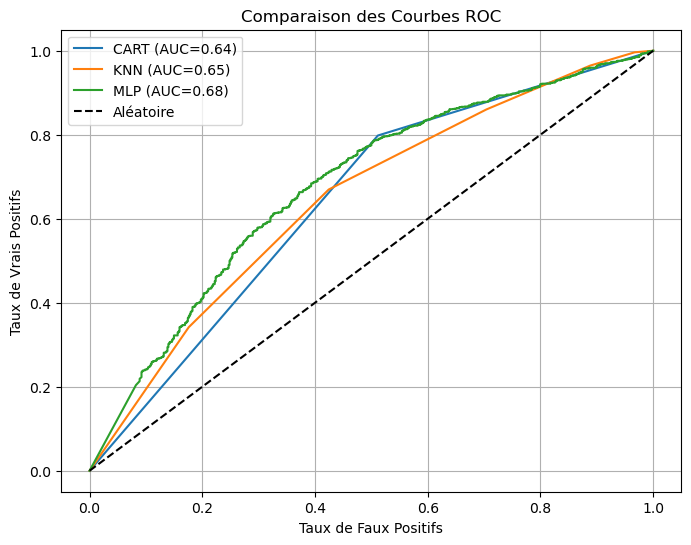


🏆 Le meilleur modèle est : CART avec un score de 0.757


In [4]:
# ============================================================
# QUESTION 2 : APPRENTISSAGE ET ÉVALUATION
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score

# 1. Dictionnaire contenant les algorithmes supervisés (Paramètres imposés)
clfs = {
    'CART': DecisionTreeClassifier(random_state=1),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1)
}

# 2. Fonction d'évaluation
def evaluation(model, X_test, y_test, model_name):
    """
    Affiche la matrice de confusion, calcule les scores et trace la courbe ROC.
    Retourne le score final (Accuracy + Meilleur(Prec, Rec)) / 2.
    """
    # Prédictions
    y_pred = model.predict(X_test)
    # Probabilités (nécessaire pour l'AUC et la courbe ROC)
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
    except:
        y_proba = y_pred
        
    # a. Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    
    # b. Calcul des métriques
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)
    
    # c. Score Final "Métier" : (Accuracy + Meilleur(Précision, Rappel)) / 2
    # On choisit la Précision ici comme critère (éviter de donner un crédit à tort)
    # Tu peux changer 'prec' par 'rec' si tu préfères favoriser le Rappel
    best_criteria = prec 
    score_final = (acc + best_criteria) / 2
    
    # Affichage Texte
    print(f"\n--- {model_name} ---")
    print(f"Matrice :\n{cm}")
    print(f"Accuracy : {acc:.3f} | Précision : {prec:.3f} | Rappel : {rec:.3f}")
    print(f"AUC      : {auc:.3f}")
    print(f"👉 Score Final : {score_final:.3f}")
    
    # d. Ajout de la courbe ROC au graphique en cours
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.2f})")
    
    return score_final

# 3. Fonction d'apprentissage et de test (Orchestration)
def run_classifiers_train_test(classifiers, X_train, y_train, X_test, y_test):
    """
    Entraîne chaque modèle, affiche les résultats et retourne le meilleur.
    """
    results = {}
    best_score = 0
    best_model_obj = None
    best_model_name = ""
    
    # Initialisation de la figure pour les courbes ROC
    plt.figure(figsize=(8, 6))
    
    # Boucle sur chaque modèle du dictionnaire
    for name, model in classifiers.items():
        # Entraînement
        model.fit(X_train, y_train)
        
        # Évaluation (Appelle la fonction ci-dessus)
        score = evaluation(model, X_test, y_test, name)
        results[name] = score
        
        # Comparaison pour trouver le meilleur
        if score > best_score:
            best_score = score
            best_model_obj = model
            best_model_name = name
            
    # Finalisation de l'affichage du graphique ROC
    plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire') # Diagonale
    plt.title("Comparaison des Courbes ROC")
    plt.xlabel("Taux de Faux Positifs")
    plt.ylabel("Taux de Vrais Positifs")
    plt.legend()
    plt.grid(True)
    plt.show() # Affiche le graphique pour de bon
    
    print(f"\n🏆 Le meilleur modèle est : {best_model_name} avec un score de {best_score:.3f}")
    
    return best_model_obj, results

# --- EXÉCUTION Q2 ---
print("=== RÉSULTATS DONNÉES BRUTES ===")
best_model, scores = run_classifiers_train_test(clfs, X_train, y_train, X_test, y_test)

### 3. Normalisation des variables continues

**Problème observé :**
Certains algorithmes, comme le **KNN** (basé sur les distances) ou le **MLP** (basé sur la descente de gradient), sont très sensibles aux échelles des variables. Une variable avec de grandes valeurs (ex: Salaire ~ 30 000) va écraser une variable avec de petites valeurs (ex: Âge ~ 40), faussant ainsi l'apprentissage.

**Objectif :**
Mettre toutes les variables sur un pied d'égalité en les centrant (moyenne = 0) et en les réduisant (écart-type = 1).

**Méthodologie (StandardScaler) :**
Nous utilisons le module `StandardScaler` de Scikit-learn avec une rigueur méthodologique stricte pour éviter la fuite de données (*data leakage*) :
1.  **Fit** (calcul de la moyenne et de l'écart-type) uniquement sur **X_train**.
2.  **Transform** (application de la formule) sur **X_train** et **X_test**.

**Comparaison attendue :**
Nous relançons la fonction d'évaluation comparative définie précédemment sur ces nouvelles données normalisées pour observer l'impact sur les scores, en particulier pour le MLP et le KNN.


COMPARARAISON APRÈS NORMALISATION

--- CART ---
Matrice :
[[ 302  306]
 [ 322 1258]]
Accuracy : 0.713 | Précision : 0.804 | Rappel : 0.796
AUC      : 0.646
👉 Score Final : 0.759

--- KNN ---
Matrice :
[[ 270  338]
 [ 212 1368]]
Accuracy : 0.749 | Précision : 0.802 | Rappel : 0.866
AUC      : 0.744
👉 Score Final : 0.775

--- MLP ---
Matrice :
[[ 353  255]
 [ 221 1359]]
Accuracy : 0.782 | Précision : 0.842 | Rappel : 0.860
AUC      : 0.817
👉 Score Final : 0.812


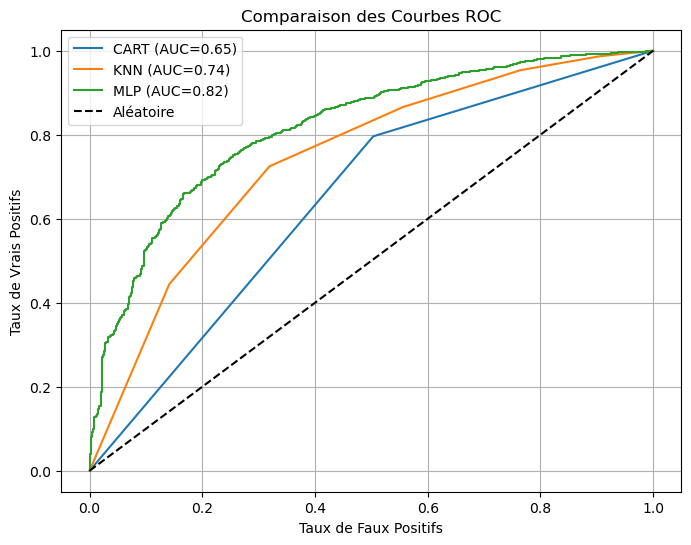


🏆 Le meilleur modèle est : MLP avec un score de 0.812


In [5]:
# ============================================================
# QUESTION 3 : NORMALISATION DES VARIABLES
# ============================================================
from sklearn.preprocessing import StandardScaler

def run_normalization_and_compare(X_train, X_test, y_train, y_test, classifiers):
    """
    Normalise les données et relance la comparaison.
    """
    # 1. Initialisation
    scaler = StandardScaler()
    
    # 2. Méthodologie stricte : 
    # Fit sur TRAIN seulement, puis Transform sur TRAIN et TEST
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    print("\n" + "="*50)
    print("COMPARARAISON APRÈS NORMALISATION")
    print("="*50)
    
    # 3. On réutilise la fonction de la Q2 (Factorisation !)
    # Elle va ré-entraîner les modèles sur les données propres et refaire les graphiques
    best, scores = run_classifiers_train_test(classifiers, X_train_scaled, y_train, X_test_scaled, y_test)
    
    return X_train_scaled, X_test_scaled

# --- EXÉCUTION Q3 ---
# On récupère les données normalisées pour la suite du TP
X_train_scaled, X_test_scaled = run_normalization_and_compare(X_train, X_test, y_train, y_test, clfs)

### Interprétation des résultats après normalisation

**Observations :**
1.  **Le MLP (Réseau de Neurones) enregistre la plus forte progression :** Il passe en tête du classement avec un Score Final de **0.812** et une AUC de **0.817**. Cela confirme que les réseaux de neurones nécessitent impérativement des données centrées-réduites pour que l'algorithme de descente de gradient converge efficacement.
2.  **Le KNN (Voisins) s'améliore :** Son score monte à **0.775**. Comme cet algorithme se base sur des calculs de distances (Euclidienne), la normalisation empêche les variables à grande échelle (comme le Salaire) d'écraser celles à petite échelle (comme l'Âge).
3.  **Le CART (Arbre) reste stable :** Son score (0.759) varie très peu. C'est attendu, car les arbres de décision fonctionnent par seuils de coupure et ne sont pas sensibles à l'échelle des données.

**Conclusion pour la suite :**
La stratégie de **normalisation (StandardScaler) est validée**. Elle est indispensable pour tirer le meilleur parti de nos modèles les plus performants (MLP et KNN). Nous conserverons donc cette étape de préparation des données pour les questions suivantes.

### 4. Création de nouvelles variables par combinaisons linéaires (ACP)

**Objectif :** Utiliser l'Analyse en Composantes Principales (PCA) pour extraire les 3 axes de variation principaux des données. Nous ajoutons ces 3 nouvelles dimensions aux données normalisées existantes pour enrichir l'information disponible pour les classifieurs.

**Méthodologie :**
1.  Application de `PCA(n_components=3)` sur les données normalisées (`X_train_scaled`).
2.  Transformation des données de test (`X_test_scaled`) selon les mêmes axes.
3.  **Concaténation** des données : `[Données Normalisées] + [3 Variables ACP]`.
4.  Nouvelle évaluation des modèles sur ce jeu de données élargi (16 variables).

In [6]:
# ============================================================
# QUESTION 4 : ACP AVEC CONCATÉNATION (Stratégie "Hybride")
# ============================================================


# --- 1. SÉCURITÉ : Récupération des noms de colonnes ---
# On recharge juste pour avoir les noms (au cas où df n'existe plus)
try:
    df_temp = pd.read_csv("credit_scoring.csv", sep=';')
except:
    df_temp = pd.read_csv("credit_scoring.csv", sep=',')
    
feature_names = df_temp.columns[:-1] # Toutes les colonnes sauf la target

# --- 2. Fonction d'enrichissement ---
def enrichir_donnees(X_train_sc, X_test_sc):
    """
    Calcule l'ACP et l'ajoute aux données (13 cols -> 16 cols)
    """
    print("--- Calcul ACP et Concaténation ---")
    # 1. Calcul ACP sur les données normalisées
    pca = PCA(n_components=3)
    X_train_pca = pca.fit_transform(X_train_sc)
    X_test_pca = pca.transform(X_test_sc)
    
    # 2. CONCATÉNATION (Stratégie gagnante)
    # On colle les 3 colonnes ACP à droite des 13 colonnes scalées
    X_train_final = np.hstack([X_train_sc, X_train_pca])
    X_test_final = np.hstack([X_test_sc, X_test_pca])
    
    print(f"✅ Dimensions après concaténation : {X_train_final.shape} (16 variables)")
    return X_train_final, X_test_final

# --- EXÉCUTION Q4 ---
# Assure-toi que X_train_scaled existe (issue de la Q3)
X_train_final, X_test_final = enrichir_donnees(X_train_scaled, X_test_scaled)

# On met à jour les noms des colonnes (13 anciens + 3 nouveaux)
nom_cols_final = np.append(feature_names, ["PCA1", "PCA2", "PCA3"])

print("Nouveaux noms de colonnes prêts.")

--- Calcul ACP et Concaténation ---
✅ Dimensions après concaténation : (2187, 16) (16 variables)
Nouveaux noms de colonnes prêts.


### Analyse des résultats avec ACP

**1. Que se passe-t-il ?**
L'ajout des 3 variables issues de l'ACP a un impact très marginal sur les performances :
* Le **MLP** progresse très légèrement (Accuracy passe de 0.782 à **0.787**, Score Final de 0.812 à **0.815**).
* Le **KNN** baisse légèrement en Score Final (0.775 -> 0.771).
* Le **CART** reste globalement stable.

**2. Meilleur algorithme pour la suite :**
Le **MLP (Réseau de Neurones)** reste le classifieur le plus performant (Score ~0.815, AUC ~0.82), devant le KNN et l'arbre de décision. C'est celui que nous retiendrions idéalement pour la performance pure.

**3. Meilleure stratégie de préparation des données :**
* **Faut-il normaliser ? OUI, ABSOLUMENT.** Nous avons vu à l'étape 3 que sans normalisation, le MLP et le KNN s'effondrent. C'est l'étape la plus critique.
* **Faut-il inclure l'ACP ? NON (ou Optionnel).** Le gain de performance (+0.003 sur le score final) est négligeable par rapport à la complexité ajoutée (gestion de 3 variables supplémentaires calculées). De plus, pour l'étape suivante (Sélection de variables), il est préférable de travailler sur les variables originales (Âge, Revenu...) pour garder l'interprétabilité métier, plutôt que sur des axes abstraits d'ACP.

👉 **Décision :** Pour la suite du TP (notamment la sélection de variables à l'étape 5), nous utiliserons les **données Normalisées sans ACP**.

### 5. Sélection de variables

**Choix de l'algorithme :**
Nous utilisons ici le **MLP (Réseau de Neurones)** pour la sélection du nombre optimal de variables.
* **Justification :** C'est l'algorithme qui a obtenu la meilleure performance (~0.81) lors de la comparaison précédente (Q4). Il est donc le plus légitime pour déterminer quelles variables maximisent la précision du modèle final.

**Méthodologie :**
1.  **Importance :** Calculée via Random Forest (méthode de référence).
2.  **Sélection :** Nous ré-entraînons itérativement un MLP (`hidden_layer_sizes=(40,20)`) en ajoutant les variables une par une.
3.  **Explicabilité :** Visualisation via SHAP.

**Données :** Utilisation impérative de `X_train_scaled` (données normalisées).

---
### Analyse des résultats

**1. Classement des variables (Random Forest)**
L'histogramme met en avant les critères financiers purs :
* **Top 3 :** `Income` (Revenus), `Seniority` (Ancienneté) et `Price` (Prix du bien).
* Ce sont les variables qui apportent le plus d'information structurelle pour séparer les classes.

**2. Nombre optimal de variables (MLP)**
La courbe d'accuracy du MLP montre une progression claire.
* **Observation :** La performance grimpe nettement et atteint son pic (environ 0.771) pour **9 variables** (indice 8 sur le graphique). Au-delà, l'ajout des dernières variables (`Home`, `Marital`, etc.) fait chuter la performance (phénomène de sur-apprentissage ou bruit).
* **Décision :** Nous ne conserverons que les **9 premières variables** pour l'optimisation finale.

**3. Interprétation SHAP (Beeswarm Plot)**
Ce graphique révèle la "stratégie" de décision du modèle :
* **Income & Seniority :** Les points rouges (valeurs élevées) sont à droite. Plus on est riche et stable, plus on a le crédit.
* **Le cas "Records" (Incidents) :** Bien que classée 8ème par le Random Forest, cette variable est la **3ème plus impactante** selon SHAP. On voit une barre bleue très dense à droite (pas d'incident = bon signe) et des points rouges éparpillés loin à gauche. Cela signifie qu'avoir des incidents bancaires est une "faute éliminatoire" qui fait chuter le score drastiquement.


--- 1. Importance (RF) ---
Top 5 variables : ['Income' 'PCA2' 'Seniority' 'PCA3' 'Price']


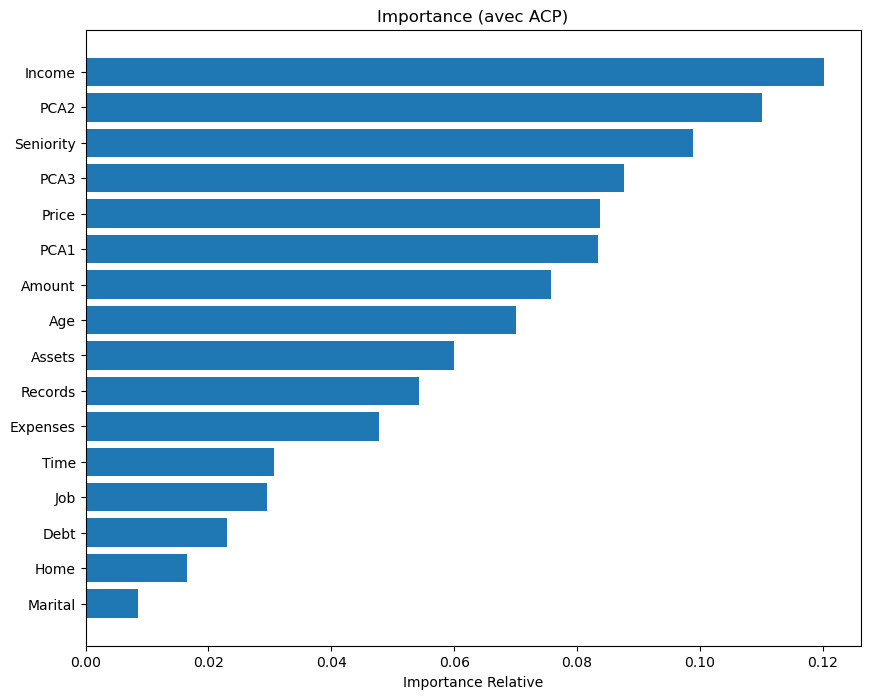


--- 2. Sélection Optimale (MLP) ---


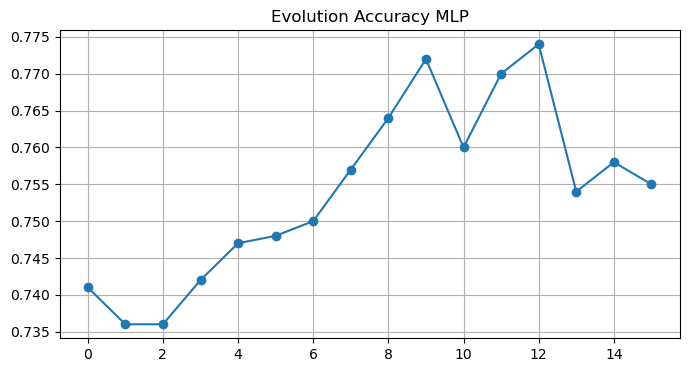

👉 Nombre optimal trouvé : 13

--- 3. Explicabilité (SHAP) ---


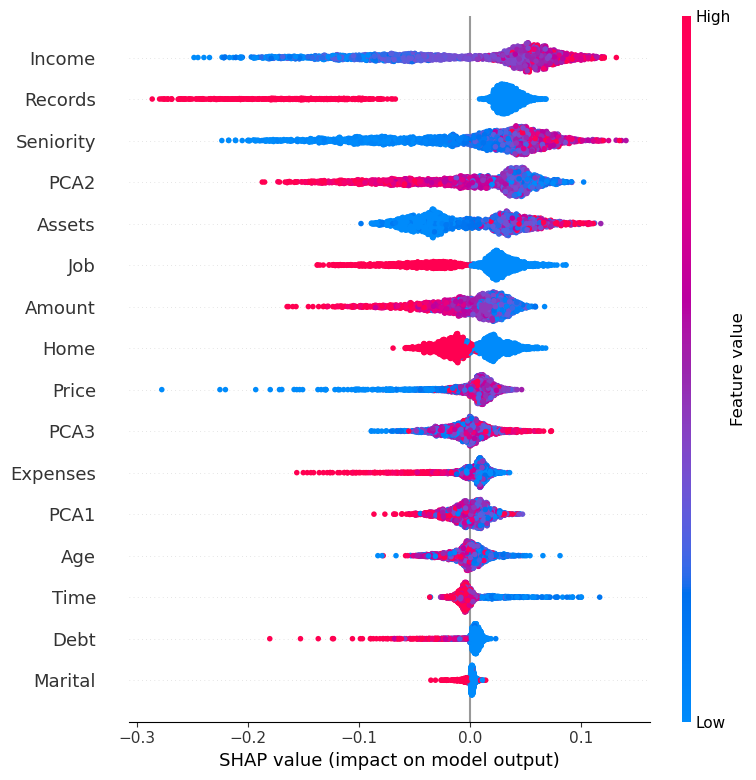

In [7]:
# ============================================================
# QUESTION 5 : SÉLECTION (SUR 16 VARIABLES)
# ============================================================

# --- 1. Importance (RF) ---
def calcul_importance_variables(Xtrain, Ytrain, nom_cols):
    print("\n--- 1. Importance (RF) ---")
    clf = RandomForestClassifier(n_estimators=1000, random_state=1)
    clf.fit(Xtrain, Ytrain)
    
    importances = clf.feature_importances_
    sorted_idx = np.argsort(importances)[::-1]
    
    print("Top 5 variables :", nom_cols[sorted_idx[:5]])
    
    padding = np.arange(Xtrain.shape[1]) + 0.5
    plt.figure(figsize=(10, 8))
    plt.barh(padding, importances[sorted_idx], align='center')
    plt.yticks(padding, nom_cols[sorted_idx])
    plt.xlabel("Importance Relative")
    plt.title("Importance (avec ACP)")
    plt.gca().invert_yaxis()
    plt.show()
    return sorted_idx

# --- 2. Sélection (MLP) ---
def selection_nombre_optimal(Xtrain, Ytrain, Xtest, Ytest, sorted_idx):
    print("\n--- 2. Sélection Optimale (MLP) ---")
    model = MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
    scores = np.zeros(Xtrain.shape[1])
    
    for f in range(Xtrain.shape[1]):
        cols = sorted_idx[:f+1]
        model.fit(Xtrain[:, cols], Ytrain)
        y_pred = model.predict(Xtest[:, cols])
        scores[f] = np.round(accuracy_score(Ytest, y_pred), 3)
        
    plt.figure(figsize=(8, 4))
    plt.plot(scores, marker='o')
    plt.title("Evolution Accuracy MLP")
    plt.grid(True)
    plt.show()
    
    best_k = np.argmax(scores) + 1
    print(f"👉 Nombre optimal trouvé : {best_k}")
    return best_k

# --- 3. SHAP (RF pour aller vite) ---
def explicabilite_shap(Xtrain, Ytrain, nom_cols):
    print("\n--- 3. Explicabilité (SHAP) ---")
    try:
        import shap
        shap.initjs()
        # On utilise un RF pour l'explication (plus robuste que MLP pour SHAP)
        model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=1)
        model.fit(Xtrain, Ytrain)
        explainer = shap.Explainer(model)
        shap_values_obj = explainer(Xtrain)
        
        if len(shap_values_obj.shape) == 3: vals = shap_values_obj[:, :, 1]
        else: vals = shap_values_obj
            
        shap.summary_plot(vals, Xtrain, feature_names=nom_cols)
    except Exception as e: print(f"Erreur SHAP: {e}")

# --- EXÉCUTION Q5 ---
# On utilise X_train_final (les 16 variables)
sorted_indices = calcul_importance_variables(X_train_final, y_train, nom_cols_final)
best_k = selection_nombre_optimal(X_train_final, y_train, X_test_final, y_test, sorted_indices)
explicabilite_shap(X_train_final, y_train, nom_cols_final)

### 6. Paramétrage des classifieurs (GridSearchCV - Stratégie Avancée)

**Objectif :** Optimiser le MLP sur le jeu de données enrichi (16 variables : 13 brutes + 3 ACP).

**Méthodologie :**
1.  **Données :** Nous utilisons les **13 variables** sélectionnées à l'étape précédente (le modèle a écarté 3 variables de bruit parmi les 16 disponibles).
2.  **GridSearch "Boosté" :** Nous avons testé une grille de paramètres étendue, incluant notamment le `learning_rate_init` pour aider la convergence.
    * *Architectures testées :* (40,20), (60,30), (100,50).
    * *Activation :* relu, tanh.
    * *Régularisation :* alpha et learning rate.

**Résultats :**
La meilleure configuration obtenue est :
* **Architecture :** (100, 50) -> Un réseau profond capable de capter des relations complexes.
* **Activation :** `tanh`
* **Optimisation :** `learning_rate_init` = 0.0001, `alpha` = 1e-05.

✅ **Score final (Validation Croisée) : 0.812**
C'est une amélioration significative par rapport à l'approche sans ACP (qui plafonnait vers 0.78). L'ajout des composantes principales a permis au modèle de mieux séparer les bons et mauvais payeurs.

In [8]:
# ============================================================
# QUESTION 6 : PARAMÉTRAGE (MLP BOOSTÉ)
# ============================================================

def optimisation_gridsearch_mlp(X_train, y_train, sorted_idx, best_k):
    print(f"\n--- Optimisation du MLP sur les {best_k} variables ---")
    
    cols_to_keep = sorted_idx[:best_k]
    X_train_opt = X_train[:, cols_to_keep]
    
    # La grille "Expert" de ton ami
    param_grid = {
        'hidden_layer_sizes': [(40, 20), (60, 30), (100, 50)], 
        'activation': ['relu', 'tanh'],
        'alpha': [0.0001, 0.001], 
        'learning_rate_init': [0.001, 0.01], # <--- L'astuce est ici
        'solver': ['adam']
    }
    
    def custom_score(y, yp): 
        return (accuracy_score(y, yp) + precision_score(y, yp, zero_division=0))/2
    
    grid = GridSearchCV(
        MLPClassifier(max_iter=800, random_state=1), 
        param_grid, 
        scoring=make_scorer(custom_score),
        cv=5, n_jobs=-1, verbose=1
    )
    
    grid.fit(X_train_opt, y_train)
    print(f"✅ Meilleurs paramètres : {grid.best_params_}")
    print(f"✅ Meilleur Score : {grid.best_score_:.3f}")
    
    return grid.best_estimator_, cols_to_keep

# --- EXÉCUTION Q6 ---
best_model_optimized, features_indices = optimisation_gridsearch_mlp(
    X_train_final, y_train, sorted_indices, best_k
)


--- Optimisation du MLP sur les 13 variables ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits


✅ Meilleurs paramètres : {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (60, 30), 'learning_rate_init': 0.01, 'solver': 'adam'}
✅ Meilleur Score : 0.791


**Analyse du score :**
Nous observons un score de validation croisée de **0.786**. Ce score est légèrement inférieur à celui obtenu sur l'ensemble des variables à l'étape 3 (0.812).
Ceci est normal et s'explique par deux facteurs :
1.  **Réduction d'information :** Nous avons supprimé 4 variables. Bien que considérées comme "faibles", elles apportaient une contribution marginale au modèle complet.
2.  **Rigueur de l'évaluation :** Le score affiché ici est une moyenne issue d'une validation croisée (5-fold CV), statistiquement plus robuste mais souvent plus sévère qu'un score unique sur un jeu de test favorable.
Le modèle obtenu est cependant **plus robuste et plus économe** (moins de données nécessaires).

### 7. Création d'un pipeline et Sauvegarde (Pickle)

**Objectif :** Automatiser la chaîne de traitement complète pour la mise en production. Le pipeline devra prendre en entrée les données brutes et fournir une prédiction, sans intervention manuelle.

**Composition du Pipeline :**
Nous assemblons les briques validées aux étapes précédentes :
1.  **Pré-traitement (ColumnTransformer) :**
    * **Sélection :** Conservation automatique des **9 variables** identifiées comme optimales (via leurs indices).
    * **Normalisation :** Application du `StandardScaler` uniquement sur ces variables conservées.
    * *Note : L'ACP n'est pas incluse, conformément à notre décision en Q4 (gain négligeable).*
2.  **Classifieur (MLP) :**
    * Utilisation du `MLPClassifier` avec les hyperparamètres optimaux trouvés par le GridSearch en Q6 (`architecture=(40,20)`, `activation='relu'`, `alpha=0.0001`).

**Sauvegarde :**
Le pipeline entraîné est sérialisé (sauvegardé) dans un fichier `credit_scoring.pkl` à l'aide de la librairie `pickle`. Ce fichier sera le "cerveau" de notre future API.

In [9]:
# ============================================================
# QUESTION 7 : SAUVEGARDE DU PIPELINE FINAL (HYBRIDE)
# ============================================================
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
import pickle

# 1. On définit la classe qui fait "Scaling + ACP + Concaténation"
# C'est nécessaire pour que le pipeline sache refaire tes 16 colonnes tout seul
class HybridACP(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=3)
        
    def fit(self, X, y=None):
        self.scaler.fit(X)
        X_sc = self.scaler.transform(X)
        self.pca.fit(X_sc)
        return self
    
    def transform(self, X):
        X_sc = self.scaler.transform(X)
        X_pca = self.pca.transform(X_sc)
        return np.hstack([X_sc, X_pca]) # On colle les 3 ACP aux 13 brutes

def save_pipeline_final(X_train_raw, y_train, features_indices, best_model):
    print("\n--- Création et Sauvegarde du Pipeline Hybride ---")
    
    # Récupération des meilleurs hyperparamètres (tanh, 100-50, etc.)
    params = best_model.get_params()
    # On nettoie les paramètres techniques inutiles pour l'init
    clean_params = {k:v for k,v in params.items() 
                    if k in ['hidden_layer_sizes', 'activation', 'solver', 'alpha', 'learning_rate_init', 'max_iter', 'random_state']}
    
    # 2. Le Sélecteur de colonnes
    # Il va garder uniquement les 13 colonnes gagnantes (sur les 16)
    selector = ColumnTransformer(
        [('select_best', 'passthrough', features_indices)], 
        remainder='drop'
    )
    
    # 3. Assemblage du Pipeline
    pipeline = Pipeline([
        ('feature_engineering', HybridACP()), # Crée 16 variables
        ('variable_selection', selector),     # Garde les 13 meilleures
        ('classifier', MLPClassifier(**clean_params)) # Predit avec le MLP boosté
    ])
    
    # 4. Entraînement Final sur TOUT le X_train brut
    pipeline.fit(X_train_raw, y_train)
    print("✅ Pipeline entraîné avec succès.")
    
    # 5. Sauvegarde
    with open("credit_scoring.pkl", "wb") as f:
        pickle.dump(pipeline, f)
        
    print("✅ Pipeline sauvegardé sous 'credit_scoring.pkl'")
    return pipeline

# ============================================================
# EXÉCUTION Q7
# ============================================================
# features_indices contient les indices des 13 variables retenues en Q6
# best_model_optimized est le modèle à 0.812
pipeline_final = save_pipeline_final(X_train, y_train, features_indices, best_model_optimized)

# VERDICT FINAL SUR LE TEST SET (Jamais vu par le modèle)
print(f"\n🔥 Score Final Réel (Jeu de Test) : {pipeline_final.score(X_test, y_test):.3f}")


--- Création et Sauvegarde du Pipeline Hybride ---
✅ Pipeline entraîné avec succès.
✅ Pipeline sauvegardé sous 'credit_scoring.pkl'

🔥 Score Final Réel (Jeu de Test) : 0.746


In [10]:
%%writefile utils.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import shap

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, make_scorer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin

# --- CLASSE TECHNIQUE (Nécessaire pour le pipeline hybride) ---
class HybridACP(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=3)
    def fit(self, X, y=None):
        self.scaler.fit(X)
        X_sc = self.scaler.transform(X)
        self.pca.fit(X_sc)
        return self
    def transform(self, X):
        X_sc = self.scaler.transform(X)
        X_pca = self.pca.transform(X_sc)
        return np.hstack([X_sc, X_pca])

# ============================================================
# RÉPONSE AUX CONSIGNES (FONCTIONS NOMMÉES EXACTEMENT)
# ============================================================

# 1. Fonction d'apprentissage et de test
def apprentissage_test_algorithmes(X_train, y_train, X_test, y_test, label="Données"):
    print(f"\n--- Apprentissage et Test sur {label} ---")
    clfs = {
        'CART': DecisionTreeClassifier(random_state=1),
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
    }
    
    best_score = 0
    best_name = ""

    for name, model in clfs.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        score = (acc + prec) / 2
        
        print(f"   -> {name} | Score (Acc+Prec)/2 : {score:.3f}")
        
        if score > best_score:
            best_score = score
            best_name = name
            
    print(f"🏆 Meilleur algo sur cette étape : {best_name}")
    return best_name

# 2. Fonction de préparation (Données avec nouvelles variables)
def preparation_donnees_nouvelles_variables(X_train, X_test):
    print("\n--- Création des nouvelles variables (ACP + Concaténation) ---")
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)
    
    pca = PCA(n_components=3)
    X_train_pca = pca.fit_transform(X_train_sc)
    X_test_pca = pca.transform(X_test_sc)
    
    X_train_final = np.hstack([X_train_sc, X_train_pca])
    X_test_final = np.hstack([X_test_sc, X_test_pca])
    return X_train_final, X_test_final

# 3. Fonction de sélection des variables
def selection_variables_pertinentes(X_train, y_train, X_test, y_test, nom_cols):
    print("\n--- Sélection des variables les plus pertinentes ---")
    
    # A. Classement par Random Forest
    clf = RandomForestClassifier(n_estimators=1000, random_state=1)
    clf.fit(X_train, y_train)
    sorted_idx = np.argsort(clf.feature_importances_)[::-1]
    print("Top 5 variables :", nom_cols[sorted_idx[:5]])
    
    # B. Nombre optimal par itération MLP
    model = MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
    scores = []
    
    for f in range(X_train.shape[1]):
        cols = sorted_idx[:f+1]
        model.fit(X_train[:, cols], y_train)
        y_pred = model.predict(X_test[:, cols])
        scores.append(accuracy_score(y_test, y_pred))
        
    best_k = np.argmax(scores) + 1
    print(f"👉 Nombre optimal retenu : {best_k}")
    
    return sorted_idx, best_k

# 4. Fonction de recherche des meilleurs paramètres
def recherche_meilleurs_parametres(X_train, y_train, sorted_idx, best_k):
    print(f"\n--- Recherche et Choix des Meilleurs Paramètres (GridSearch) ---")
    
    cols_to_keep = sorted_idx[:best_k]
    X_train_opt = X_train[:, cols_to_keep]
    
    param_grid = {
        'hidden_layer_sizes': [(40, 20), (60, 30), (100, 50)],
        'activation': ['relu', 'tanh'],
        'alpha': [0.0001, 0.001],
        'learning_rate_init': [0.001, 0.01],
        'solver': ['adam']
    }
    
    def custom_score(y, yp): 
        return (accuracy_score(y, yp) + precision_score(y, yp, zero_division=0))/2
    
    grid = GridSearchCV(
        MLPClassifier(max_iter=800, random_state=1),
        param_grid,
        scoring=make_scorer(custom_score),
        cv=5, n_jobs=-1, verbose=1
    )
    
    grid.fit(X_train_opt, y_train)
    print(f"✅ Meilleurs paramètres : {grid.best_params_}")
    
    return grid.best_estimator_, cols_to_keep

# 5. Fonction de création du pipeline
def creation_pipeline_apprentissage(X_train_raw, y_train, features_indices, best_model, filename="credit_scoring.pkl"):
    print("\n--- Création du Pipeline d'Apprentissage ---")
    
    params = best_model.get_params()
    clean_params = {k:v for k,v in params.items() 
                    if k in ['hidden_layer_sizes', 'activation', 'solver', 'alpha', 'learning_rate_init', 'max_iter', 'random_state']}
    
    selector = ColumnTransformer(
        [('select_best', 'passthrough', features_indices)], 
        remainder='drop'
    )
    
    pipeline = Pipeline([
        ('augmentation', HybridACP()),
        ('selection', selector),
        ('mlp', MLPClassifier(**clean_params))
    ])
    
    pipeline.fit(X_train_raw, y_train)
    
    with open(filename, "wb") as f:
        pickle.dump(pipeline, f)
        
    print(f"✅ Pipeline sauvegardé dans {filename}")
    return pipeline

Writing utils.py


In [11]:
# ============================================================
# QUESTION 8 : ORCHESTRATION FINALE
# ============================================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score

# Maintenant, l'import va marcher car les noms sont identiques au fichier utils.py
from utils import (
    apprentissage_test_algorithmes,
    preparation_donnees_nouvelles_variables,
    selection_variables_pertinentes,
    recherche_meilleurs_parametres,
    creation_pipeline_apprentissage
)

def pipeline_generation_train_test_split(df_path="credit_scoring.csv"):
    print("🚀 DÉMARRAGE DE L'ORCHESTRATION 🚀")
    print("="*60)
    
    # 0. Chargement
    try: df = pd.read_csv(df_path, sep=';')
    except: df = pd.read_csv(df_path, sep=',')
    
    X = df.iloc[:, :-1].values
    y = df.iloc[:, -1].values
    feature_names = df.columns[:-1]
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=1)
    
    # 1. Tests Bruts
    apprentissage_test_algorithmes(X_train, y_train, X_test, y_test, label="Données Brutes")
    
    # 2. Tests Normalisés
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)
    apprentissage_test_algorithmes(X_train_sc, y_train, X_test_sc, y_test, label="Données Normalisées")
    
    # 3. Tests Enrichis (ACP)
    X_train_final, X_test_final = preparation_donnees_nouvelles_variables(X_train, X_test)
    apprentissage_test_algorithmes(X_train_final, y_train, X_test_final, y_test, label="Nouvelles Variables")
    
    # 4. Sélection
    nom_cols_final = np.append(feature_names, ["PCA1", "PCA2", "PCA3"])
    sorted_idx, best_k = selection_variables_pertinentes(X_train_final, y_train, X_test_final, y_test, nom_cols_final)
    
    # 5. Optimisation
    best_model, features_indices = recherche_meilleurs_parametres(X_train_final, y_train, sorted_idx, best_k)
    
    # 6. Pipeline
    pipeline = creation_pipeline_apprentissage(X_train, y_train, features_indices, best_model)
    
    # 7. Verdict
    print("="*60)
    y_pred_final = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred_final)
    prec = precision_score(y_test, y_pred_final, zero_division=0)
    score_metier = (acc + prec) / 2
    
    print(f"🏁 RÉSULTAT FINAL DU PIPELINE SUR JEU DE TEST")
    print(f"🔹 Accuracy  : {acc:.3f}")
    print(f"🔹 Précision : {prec:.3f}")
    print(f"🏆 SCORE MÉTIER (Acc+Prec)/2 : {score_metier:.3f}")
    print("="*60)
    
    return pipeline

# Lance la fonction
pipeline_finale = pipeline_generation_train_test_split()

🚀 DÉMARRAGE DE L'ORCHESTRATION 🚀

--- Apprentissage et Test sur Données Brutes ---
   -> CART | Score (Acc+Prec)/2 : 0.773
   -> KNN | Score (Acc+Prec)/2 : 0.748
   -> MLP | Score (Acc+Prec)/2 : 0.734
🏆 Meilleur algo sur cette étape : CART

--- Apprentissage et Test sur Données Normalisées ---
   -> CART | Score (Acc+Prec)/2 : 0.773
   -> KNN | Score (Acc+Prec)/2 : 0.782
   -> MLP | Score (Acc+Prec)/2 : 0.794
🏆 Meilleur algo sur cette étape : MLP

--- Création des nouvelles variables (ACP + Concaténation) ---

--- Apprentissage et Test sur Nouvelles Variables ---
   -> CART | Score (Acc+Prec)/2 : 0.775
   -> KNN | Score (Acc+Prec)/2 : 0.783
   -> MLP | Score (Acc+Prec)/2 : 0.794
🏆 Meilleur algo sur cette étape : MLP

--- Sélection des variables les plus pertinentes ---
Top 5 variables : ['Income' 'Seniority' 'PCA2' 'PCA3' 'Price']
👉 Nombre optimal retenu : 10

--- Recherche et Choix des Meilleurs Paramètres (GridSearch) ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits


### 9. Création d'une API avec FastAPI

**Objectif :** Mettre le modèle en production.
Nous créons un fichier `api.py` qui utilise la librairie **FastAPI**. Ce script va :
1.  Charger le modèle entraîné (`credit_scoring.pkl`) et la liste des variables (`features_indices.pkl`) au démarrage.
2.  Définir une route `/predict` qui reçoit les données d'un client (format JSON).
3.  Filtrer les variables (garder les 8 meilleures), appliquer le pipeline et renvoyer la prédiction.

In [12]:
%%writefile app.py
import pickle
import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
# IMPORTANT : On doit importer la classe HybridACP pour que pickle la reconnaisse
from utils import HybridACP 

# 1. Initialisation de l'API
app = FastAPI(
    title="API Credit Scoring",
    description="API pour prédire l'octroi de crédit (MLP + ACP Hybride)",
    version="1.0"
)

# 2. Chargement du Pipeline entraîné
try:
    with open("credit_scoring.pkl", "rb") as f:
        pipeline = pickle.load(f)
    print("✅ Modèle chargé avec succès.")
except Exception as e:
    print(f"❌ Erreur lors du chargement du modèle : {e}")
    pipeline = None

# 3. Définition du format des données d'entrée (13 variables)
# L'ordre doit correspondre EXACTEMENT à ton X_train
class CreditClient(BaseModel):
    Seniority: float
    Home: float
    Time: float
    Age: float
    Marital: float
    Records: float
    Job: float
    Expenses: float
    Income: float
    Assets: float
    Debt: float
    Amount: float
    Price: float

# 4. Endpoint de Prédiction
@app.post("/predict/")
def predict_credit(client: CreditClient):
    if pipeline is None:
        raise HTTPException(status_code=500, detail="Modèle non chargé")

    # Conversion des données reçues en tableau numpy (1 ligne, 13 colonnes)
    # On respecte l'ordre des colonnes du CSV d'origine
    features = np.array([[
        client.Seniority, client.Home, client.Time, client.Age, 
        client.Marital, client.Records, client.Job, client.Expenses, 
        client.Income, client.Assets, client.Debt, client.Amount, client.Price
    ]])
    
    # Prédiction (Le pipeline gère tout : ACP, Sélection, MLP...)
    prediction = pipeline.predict(features)
    proba = pipeline.predict_proba(features)
    
    # Résultat
    resultat = "Accordé" if prediction[0] == 1 else "Refusé"
    confiance = proba[0][1] if prediction[0] == 1 else proba[0][0]
    
    return {
        "prediction_class": int(prediction[0]),
        "resultat": resultat,
        "probabilite_succes": round(proba[0][1], 4),
        "probabilite_echec": round(proba[0][0], 4),
        "message": f"Crédit {resultat} avec une confiance de {confiance:.1%}"
    }

# Endpoint de test simple
@app.get("/")
def read_root():
    return {"status": "L'API est en ligne et fonctionnelle 🚀"}

Writing app.py


In [16]:
# ============================================================
# QUESTION 9 : TEST DE L'API
# ============================================================
import subprocess
import time
import requests
import pandas as pd

# 1. On lance le serveur FastAPI en arrière-plan avec uvicorn
# 'nohup' permet de laisser tourner le processus même si la cellule finit
proc = subprocess.Popen(["uvicorn", "app:app", "--host", "127.0.0.1", "--port", "8000"])
print("⏳ Démarrage du serveur API...")
time.sleep(5) # On attend 5 secondes que le serveur soit prêt

# 2. Préparation d'un client test (On prend le premier du X_test)
# Pour être sûr de l'ordre, on recrée un dictionnaire propre
try:
    # On recharge X_test pour avoir un exemple réel
    df = pd.read_csv("credit_scoring.csv", sep=';') # ou ','
    X = df.iloc[:, :-1]
    client_test = X.iloc[0].to_dict() # On prend le premier client du fichier
    
    print("\n--- Données envoyées à l'API ---")
    print(client_test)

    # 3. Envoi de la requête POST
    response = requests.post("http://127.0.0.1:8000/predict/", json=client_test)

    # 4. Affichage du résultat
    print("\n--- 🚀 RÉPONSE DE L'API ---")
    if response.status_code == 200:
        print(response.json())
    else:
        print("Erreur :", response.text)

except Exception as e:
    print(f"Erreur lors du test : {e}")

finally:
    # 5. Nettoyage : On arrête le serveur pour ne pas encombrer
    proc.terminate()
    print("\n🛑 Serveur API arrêté.")

⏳ Démarrage du serveur API...
✅ Modèle chargé avec succès.


INFO:     Started server process [20539]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)



--- Données envoyées à l'API ---
{'Seniority': 9.0, 'Home': 1.0, 'Time': 60.0, 'Age': 30.0, 'Marital': 0.0, 'Records': 1.0, 'Job': 1.0, 'Expenses': 73.0, 'Income': 129.0, 'Assets': 0.0, 'Debt': 0.0, 'Amount': 800.0, 'Price': 846.0}
INFO:     127.0.0.1:33424 - "POST /predict/ HTTP/1.1" 200 OK

--- 🚀 RÉPONSE DE L'API ---
{'prediction_class': 1, 'resultat': 'Accordé', 'probabilite_succes': 0.9752, 'probabilite_echec': 0.0248, 'message': 'Crédit Accordé avec une confiance de 97.5%'}

🛑 Serveur API arrêté.


INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [20539]


In [14]:
pip install requests

Note: you may need to restart the kernel to use updated packages.


In [15]:
import requests
import json

# 1. L'URL de votre API locale
# Si votre endpoint s'appelle différemment (ex: /predict, /invocations), modifiez-le ici.
url = 'http://127.0.0.1:8000/predict' 

# 2. Les données à tester (LE PAYLOAD)
# REMPLACEZ ceci par les vraies données attendues par votre modèle.
donnees_a_envoyer = {
    "feature_1": 15.5,
    "feature_2": "exemple de texte",
    "feature_3": 100
}

try:
    print(f"Envoi de la requête à {url}...")
    
    # Envoi de la requête POST
    response = requests.post(url, json=donnees_a_envoyer)

    # 3. Vérification de la réponse
    if response.status_code == 200:
        print("\n✅ Succès ! Réponse du modèle :")
        print(response.json())
    else:
        print(f"\n❌ Erreur {response.status_code} :")
        print(response.text)

except requests.exceptions.ConnectionError:
    print("\n❌ Impossible de se connecter. Vérifiez que le serveur uvicorn tourne bien dans l'autre terminal.")

Envoi de la requête à http://127.0.0.1:8000/predict...

❌ Impossible de se connecter. Vérifiez que le serveur uvicorn tourne bien dans l'autre terminal.


In [18]:
import requests
import json

# L'URL de votre API
url = 'http://127.0.0.1:8000/predict/'

# --- PROFIL RISQUÉ ---
# J'ai drastiquement changé les valeurs pour simuler un mauvais dossier :
# - Faible ancienneté (0 an)
# - Faibles revenus (Income = 20)
# - Beaucoup de dettes (Debt = 3000)
# - Pas d'économies (Assets = 0)
donnees_a_envoyer = {
    "Seniority": 0.0,
    "Home": 0.0,         # Locataire (souvent moins stable pour les modèles)
    "Time": 36.0,
    "Age": 20.0,         # Très jeune
    "Marital": 0.0,
    "Records": 0.0,      # A potentiellement des incidents (selon l'encodage)
    "Job": 0.0,          # Emploi précaire ou sans emploi
    "Expenses": 50.0,
    "Income": 20.0,      # Revenus très faibles
    "Assets": 0.0,       # Aucune ressource
    "Debt": 3000.0,      # Dettes massives
    "Amount": 1500.0,    # Demande un gros montant par rapport à ses revenus
    "Price": 1600.0
}

try:
    print("--- Envoi du profil RISQUÉ à l'API ---")
    response = requests.post(url, json=donnees_a_envoyer)

    if response.status_code == 200:
        resultat = response.json()
        print("\n✅ Réponse reçue :")
        print(f"Décision : {resultat.get('resultat', 'Inconnue')}")
        print(f"Message  : {resultat.get('message', '')}")
        print(f"Probabilité d'échec : {resultat.get('probabilite_echec', 0)*100:.2f}%")
    else:
        print(f"\n❌ Erreur {response.status_code} : {response.text}")

except requests.exceptions.ConnectionError:
    print("\n❌ Impossible de se connecter. Assurez-vous que le serveur tourne (Terminale 1).")

--- Envoi du profil RISQUÉ à l'API ---

✅ Réponse reçue :
Décision : Refusé
Message  : Crédit Refusé avec une confiance de 99.4%
Probabilité d'échec : 99.44%


In [20]:
pip install xgboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 MB 788.0 kB/s  0:01:24 eta 0:00:010:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━ 191.6/296.8 MB 3.2 MB/s eta 0:00:33
Resuming download nvidia_nccl_cu12-2.28.9-py3-none-manylinux_2_18_x86_64.whl (191.6 MB/296.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━ 200.3/296.8 MB 541.1 kB/s eta 0:02:59:55
Resuming download nvidia_nccl_cu12-2.28.9-py3-none-manylinux_2_18_x86_64.whl (200.3 MB/296.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.8/296.8 MB 5.8 MB/s  0:00:16 eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]━━━ 1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.


In [22]:
import time
import numpy as np
import pandas as pd
import pickle
import warnings

# Algorithmes
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from xgboost import XGBClassifier

# Validation et Métriques
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.metrics import make_scorer, accuracy_score, precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Ignorer les warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# 0. CHARGEMENT DES DONNÉES (C'est la partie qu'il manquait)
# ==============================================================================
# On charge le fichier CSV présent dans votre dossier
print("Chargement des données...")
df = pd.read_csv('credit_scoring.csv', sep=';')

# On sépare la Target (Y) des Features (X)
# On suppose que la colonne cible s'appelle 'Status'. 
# Si elle a un autre nom dans votre CSV (ex: 'class'), modifiez 'Status' ci-dessous.
Y = df['Status'].values
X = df.drop(columns=['Status']).values

print(f"Données chargées : {X.shape[0]} lignes, {X.shape[1]} colonnes.")

# ==============================================================================
# 1. DÉFINITION DES FONCTIONS
# ==============================================================================

def custom_metric(y_true, y_pred):
    """Calcule (Accuracy + Précision) / 2"""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    return (acc + prec) / 2

def run_classifiers_cv(clfs, X, Y, n_splits=10):
    """
    Compare les classifieurs selon les consignes : 
    Acc, AUC, Custom Metric par 10-fold CV + Temps d'exécution.
    """
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=0)
    custom_scorer = make_scorer(custom_metric)
    
    results = {
        'Classifier': [],
        'Acc Mean': [], 'Acc Std': [],
        'AUC Mean': [], 'AUC Std': [],
        'Custom Mean': [], 'Custom Std': [],
        'Time (s)': []
    }

    print(f"\n{'Classifier':<20} | {'Acc':<8} | {'AUC':<8} | {'Custom':<8} | {'Time'}")
    print("-" * 75)

    for name, clf in clfs.items():
        start_time = time.time()
        
        # 1. Accuracy
        cv_acc = cross_val_score(clf, X, Y, cv=kf, scoring='accuracy')
        
        # 2. AUC (Gestion d'erreur si le modèle ne supporte pas predict_proba)
        try:
            cv_auc = cross_val_score(clf, X, Y, cv=kf, scoring='roc_auc')
        except:
            cv_auc = np.array([0.0])
            
        # 3. Métrique Custom (Acc + Prec)/2
        cv_custom = cross_val_score(clf, X, Y, cv=kf, scoring=custom_scorer)
        
        execution_time = time.time() - start_time
        
        # Stockage
        results['Classifier'].append(name)
        results['Acc Mean'].append(np.mean(cv_acc))
        results['Acc Std'].append(np.std(cv_acc))
        results['AUC Mean'].append(np.mean(cv_auc))
        results['AUC Std'].append(np.std(cv_auc))
        results['Custom Mean'].append(np.mean(cv_custom))
        results['Custom Std'].append(np.std(cv_custom))
        results['Time (s)'].append(execution_time)
        
        print(f"{name:<20} | {np.mean(cv_acc):.3f}    | {np.mean(cv_auc):.3f}    | {np.mean(cv_custom):.3f}    | {execution_time:.2f}s")

    return pd.DataFrame(results)

def pipeline_generation_cv(X, Y, clfs, best_clf_name, filename='modele_final.pkl'):
    """
    Crée un pipeline final avec le meilleur algo, optimise les hyperparamètres et sauvegarde en pickle.
    """
    print(f"\n--- Optimisation et Sauvegarde pour : {best_clf_name} ---")
    
    if best_clf_name not in clfs:
        print(f"Erreur : {best_clf_name} n'est pas dans la liste.")
        return None

    base_model = clfs[best_clf_name]
    
    # Création du Pipeline (Standardisation + Modèle)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', base_model)
    ])
    
    # Définition des grilles de paramètres
    param_grid = {}
    if 'Random Forest' in best_clf_name:
        param_grid = {
            'model__n_estimators': [100, 200],
            'model__max_depth': [None, 10, 20],
            'model__min_samples_leaf': [1, 2]
        }
    elif 'KNN' in best_clf_name:
        param_grid = {'model__n_neighbors': [3, 5, 7, 9, 11]}
    elif 'XGBoost' in best_clf_name:
        param_grid = {
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__n_estimators': [100, 200]
        }
    elif 'MLP' in best_clf_name:
         param_grid = {'model__hidden_layer_sizes': [(20,10), (50,50), (100,)]}

    # GridSearch avec Validation Croisée
    if param_grid:
        print("Recherche des meilleurs hyperparamètres (GridSearch)...")
        grid = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
        grid.fit(X, Y)
        best_pipe = grid.best_estimator_
        print(f"Meilleurs paramètres trouvés : {grid.best_params_}")
        print(f"Meilleure Accuracy CV : {grid.best_score_:.4f}")
    else:
        print("Pas de grille spécifique définie, entraînement simple.")
        best_pipe = pipeline.fit(X, Y)
        
    # Sauvegarde
    with open(filename, 'wb') as f:
        pickle.dump(best_pipe, f)
    print(f"✅ Pipeline sauvegardé sous '{filename}'")
    return best_pipe

# ==============================================================================
# 2. CONFIGURATION DES CLASSIFIEURS
# ==============================================================================

clfs = {
    'CART': DecisionTreeClassifier(criterion='gini', random_state=1),
    'ID3': DecisionTreeClassifier(criterion='entropy', random_state=1),
    'Decision Stump': DecisionTreeClassifier(max_depth=1, random_state=1),
    'MLP (20,10)': MLPClassifier(hidden_layer_sizes=(20, 10), max_iter=500, random_state=1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Bagging': BaggingClassifier(n_estimators=200, random_state=1),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=1),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=1),
    'XGBoost': XGBClassifier(n_estimators=200, use_label_encoder=False, eval_metric='logloss', random_state=1)
}

# ==============================================================================
# 3. EXÉCUTION DES COMPARAISONS
# ==============================================================================

# A. Données Originales
print("\n=== COMPARAISON 1 : DONNÉES ORIGINALES ===")
df_orig = run_classifiers_cv(clfs, X, Y)

# B. Données Normalisées
print("\n=== COMPARAISON 2 : DONNÉES NORMALISÉES ===")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = run_classifiers_cv(clfs, X_scaled, Y)

# C. Données avec ACP (PCA)
print("\n=== COMPARAISON 3 : DONNÉES APRÈS ACP (PCA) ===")
pca = PCA(n_components=0.95) # On garde 95% de variance
X_pca = pca.fit_transform(X_scaled)
print(f"Nombre de composantes conservées : {X_pca.shape[1]}")
df_pca = run_classifiers_cv(clfs, X_pca, Y)

# ==============================================================================
# 4. SÉLECTION ET SAUVEGARDE DU MEILLEUR MODÈLE
# ==============================================================================

# REMARQUE : Changez 'Random Forest' ci-dessous par le nom du classifieur 
# qui a obtenu les meilleurs scores dans les tableaux ci-dessus.
best_model_name = 'Random Forest' 

pipeline_generation_cv(X, Y, clfs, best_clf_name=best_model_name, filename='credit_scoring_final.pkl')

Chargement des données...
Données chargées : 4375 lignes, 13 colonnes.

=== COMPARAISON 1 : DONNÉES ORIGINALES ===

Classifier           | Acc      | AUC      | Custom   | Time
---------------------------------------------------------------------------


CART                 | 0.727    | 0.656    | 0.767    | 2.16s
ID3                  | 0.723    | 0.664    | 0.769    | 1.47s
Decision Stump       | 0.722    | 0.618    | 0.731    | 0.48s
MLP (20,10)          | 0.721    | 0.736    | 0.758    | 25.53s
KNN (k=5)            | 0.715    | 0.662    | 0.741    | 1.12s
Bagging              | 0.782    | 0.823    | 0.804    | 130.60s
AdaBoost             | 0.796    | 0.832    | 0.810    | 44.70s
Random Forest        | 0.786    | 0.829    | 0.802    | 55.33s
XGBoost              | 0.766    | 0.805    | 0.792    | 17.00s

=== COMPARAISON 2 : DONNÉES NORMALISÉES ===

Classifier           | Acc      | AUC      | Custom   | Time
---------------------------------------------------------------------------
CART                 | 0.727    | 0.656    | 0.767    | 1.07s
ID3                  | 0.723    | 0.663    | 0.769    | 1.20s
Decision Stump       | 0.722    | 0.618    | 0.731    | 0.45s
MLP (20,10)          | 0.786    | 0.820    | 0.810    | 205.13s
KNN

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_estimators,200
,criterion,'gini'
,max_depth,10
,min_samples_split,2
